# Homework 4 Programming Exercises

This notebook covers Programming Exercises 1 and 2. Run the cells from top to bottom from the `hw4` folder. The data are stored in `data/`; the figures are saved in `figures/`. The written exercises are provided in the report.

The EM updates are implemented below with NumPy and SciPy. Scikit-learn is used for the K-means comparison and the permitted logistic regression models.

In [1]:
from pathlib import Path
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from scipy.linalg import eigh
from scipy.special import logsumexp
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier

ROOT = Path.cwd()
DATA = ROOT / "data"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
RNG_SEED = 5785
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180, "font.size": 10})

## Programming Exercise 1: two-component Gaussian mixture

### Part (a): load and plot Old Faithful

Each row contains eruption duration and waiting time, both in minutes. We load all 272 observations and plot them to see whether two groups are plausible.

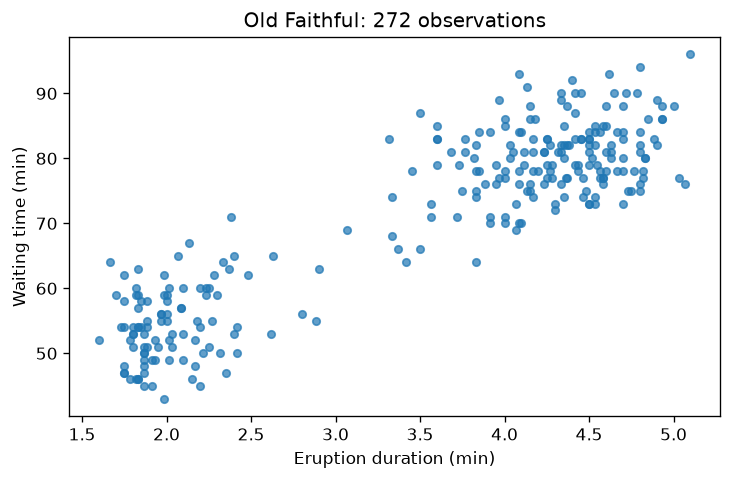

In [2]:
rows = []
for line in (DATA / "faithful.dat").read_text().splitlines():
    parts = line.split()
    if len(parts) == 3 and parts[0].isdigit():
        rows.append([float(parts[1]), float(parts[2])])
X = np.asarray(rows, dtype=float)
assert X.shape == (272, 2), X.shape

fig, ax = plt.subplots(figsize=(6.2, 4.1))
ax.scatter(X[:, 0], X[:, 1], s=20, alpha=.7)
ax.set(xlabel="Eruption duration (min)", ylabel="Waiting time (min)",
       title="Old Faithful: 272 observations")
fig.tight_layout()
fig.savefig(FIG / "faithful_scatter.png")
plt.show()

### Parts (b) and (c): E-step and M-step

The E-step assigns a probability to each component for every point. A point can partly belong to both components; its two probabilities must sum to one.

$$\gamma_{ik}=\frac{\phi_k\mathcal{N}(x_i\mid\mu_k,\Sigma_k)}{\sum_j\phi_j\mathcal{N}(x_i\mid\mu_j,\Sigma_j)}.$$

With $N_k=\sum_i\gamma_{ik}$, the M-step treats these probabilities as weights:

$$\phi_k=\frac{N_k}{n},\quad\mu_k=\frac{\sum_i\gamma_{ik}x_i}{N_k},\quad\Sigma_k=\frac{\sum_i\gamma_{ik}(x_i-\mu_k)(x_i-\mu_k)^T}{N_k}.$$

### Part (d): implement and run EM

The following cell implements the density calculation and both updates directly. It uses full covariances with a small diagonal ridge, tries ten seeded starts, and keeps the highest final log likelihood. EM stops when $|L_{new}-L_{old}|\leq10^{-8}(1+|L_{old}|)$, or at 500 iterations. The threshold checks that further updates make negligible progress. The plots show the mean trajectories and likelihood history.


EM selected seed: 5791
EM iterations / converged: 11 True
EM log likelihood: -1130.26396
EM weights: [0.35587 0.64413]
EM means (eruption, waiting):
 [[ 2.03639 54.47855]
 [ 4.28966 79.96815]]
EM covariances:
 [[[ 0.06917  0.4352 ]
  [ 0.4352  33.69748]]

 [[ 0.16997  0.94056]
  [ 0.94056 36.04566]]]
EM hard cluster counts: [ 97 175]


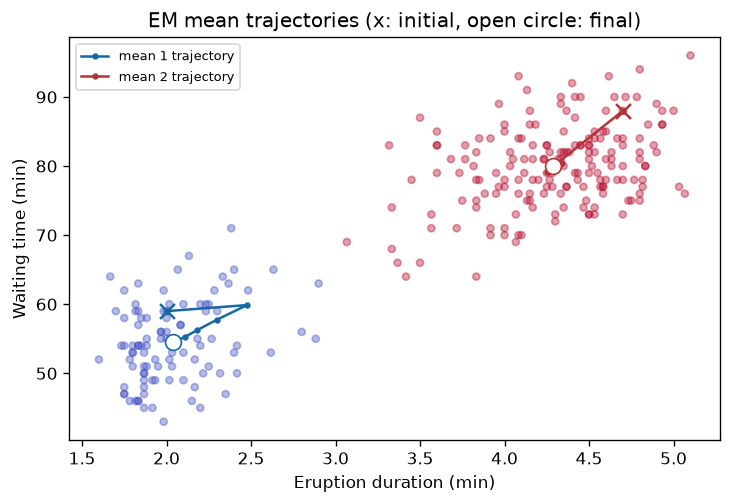

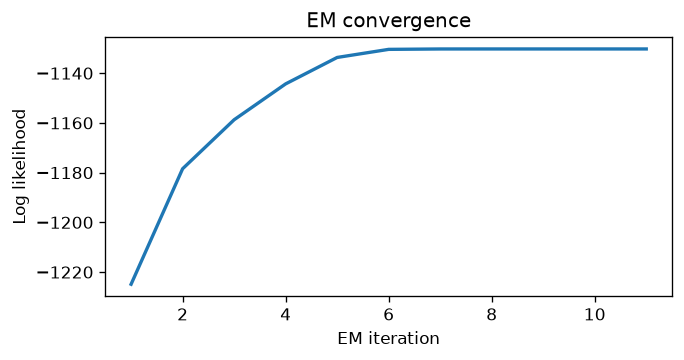

In [3]:
def log_gaussian(x, mu, covariance):
    sign, logdet = np.linalg.slogdet(covariance)
    if sign <= 0:
        raise ValueError("Covariance must be positive definite")
    centered = x - mu
    mahal = np.sum(centered * np.linalg.solve(covariance, centered.T).T, axis=1)
    d = x.shape[1]
    return -.5 * (d * np.log(2 * np.pi) + logdet + mahal)


def e_step(x, weights, means, covariances):
    log_joint = np.column_stack([
        np.log(weights[k]) + log_gaussian(x, means[k], covariances[k])
        for k in range(len(weights))
    ])
    log_marginal = logsumexp(log_joint, axis=1)
    responsibilities = np.exp(log_joint - log_marginal[:, None])
    return responsibilities, float(log_marginal.sum())


def m_step(x, responsibilities, ridge=1e-6):
    n, d = x.shape
    effective_sizes = responsibilities.sum(axis=0)
    weights = effective_sizes / n
    means = (responsibilities.T @ x) / effective_sizes[:, None]
    covariances = np.empty((responsibilities.shape[1], d, d))
    for k in range(len(weights)):
        centered = x - means[k]
        covariances[k] = (
            (centered * responsibilities[:, k, None]).T @ centered
            / effective_sizes[k]
        ) + ridge * np.eye(d)
    return weights, means, covariances


def fit_em(x, seed, max_iter=500, relative_tolerance=1e-8):
    rng = np.random.default_rng(seed)
    initial = rng.choice(len(x), size=2, replace=False)
    means = x[initial].copy()
    weights = np.full(2, .5)
    common_cov = np.cov(x, rowvar=False) + 1e-6 * np.eye(2)
    covariances = np.repeat(common_cov[None, :, :], 2, axis=0)
    trajectory = [means.copy()]
    likelihoods = []
    converged = False
    for iteration in range(1, max_iter + 1):
        responsibilities, old_ll = e_step(x, weights, means, covariances)
        weights, means, covariances = m_step(x, responsibilities)
        trajectory.append(means.copy())
        _, new_ll = e_step(x, weights, means, covariances)
        likelihoods.append(new_ll)
        if new_ll < old_ll - 1e-5:
            raise AssertionError("EM log likelihood decreased")
        if abs(new_ll - old_ll) <= relative_tolerance * (1 + abs(old_ll)):
            converged = True
            break
    return dict(seed=seed, weights=weights, means=means,
                covariances=covariances, trajectory=np.array(trajectory),
                likelihoods=np.array(likelihoods), iterations=iteration,
                converged=converged)


# Ten reproducible random starts reduce sensitivity to the local optimum.
em_runs = [fit_em(X, RNG_SEED + j) for j in range(10)]
em = max(em_runs, key=lambda run: run["likelihoods"][-1])
# Sort components by eruption duration for stable reporting.
order = np.argsort(em["means"][:, 0])
for key in ("weights", "means", "covariances"):
    em[key] = em[key][order]
em["trajectory"] = em["trajectory"][:, order]
gamma, final_ll = e_step(X, em["weights"], em["means"], em["covariances"])
em_labels = gamma.argmax(axis=1)

print("EM selected seed:", em["seed"])
print("EM iterations / converged:", em["iterations"], em["converged"])
print("EM log likelihood:", round(final_ll, 5))
print("EM weights:", np.round(em["weights"], 5))
print("EM means (eruption, waiting):\n", np.round(em["means"], 5))
print("EM covariances:\n", np.round(em["covariances"], 5))
print("EM hard cluster counts:", np.bincount(em_labels, minlength=2))

fig, ax = plt.subplots(figsize=(6.2, 4.3))
ax.scatter(X[:, 0], X[:, 1], c=em_labels, cmap="coolwarm", s=18, alpha=.38)
for k, color in enumerate(("#1668a5", "#b43339")):
    path = em["trajectory"][:, k, :]
    ax.plot(path[:, 0], path[:, 1], "-o", color=color, markersize=2.8,
            lw=1.5, label=f"mean {k+1} trajectory")
    ax.scatter(*path[0], color=color, marker="x", s=80, zorder=5)
    ax.scatter(*path[-1], facecolors="white", edgecolors=color,
               marker="o", s=90, zorder=6)
ax.set(xlabel="Eruption duration (min)", ylabel="Waiting time (min)",
       title="EM mean trajectories (x: initial, open circle: final)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "em_trajectories.png")
plt.show()

fig, ax = plt.subplots(figsize=(5.8, 3.1))
ax.plot(np.arange(1, len(em["likelihoods"]) + 1), em["likelihoods"], lw=2)
ax.set(xlabel="EM iteration", ylabel="Log likelihood",
       title="EM convergence")
fig.tight_layout()
fig.savefig(FIG / "em_likelihood.png")
plt.show()

### Part (e): compare with K-means

We use K=2 on the same raw features. Before counting disagreements, we align the cluster labels by eruption duration; cluster numbers themselves have no meaning. K-means uses Euclidean distance and hard assignments, while the GMM can account for unequal, correlated spreads. The supplied data give 5 different assignments out of 272.

K-means centers:
 [[ 2.09433 54.75   ]
 [ 4.29793 80.28488]]
K-means hard cluster counts: [100 172]
Different hard assignments: 5 of 272


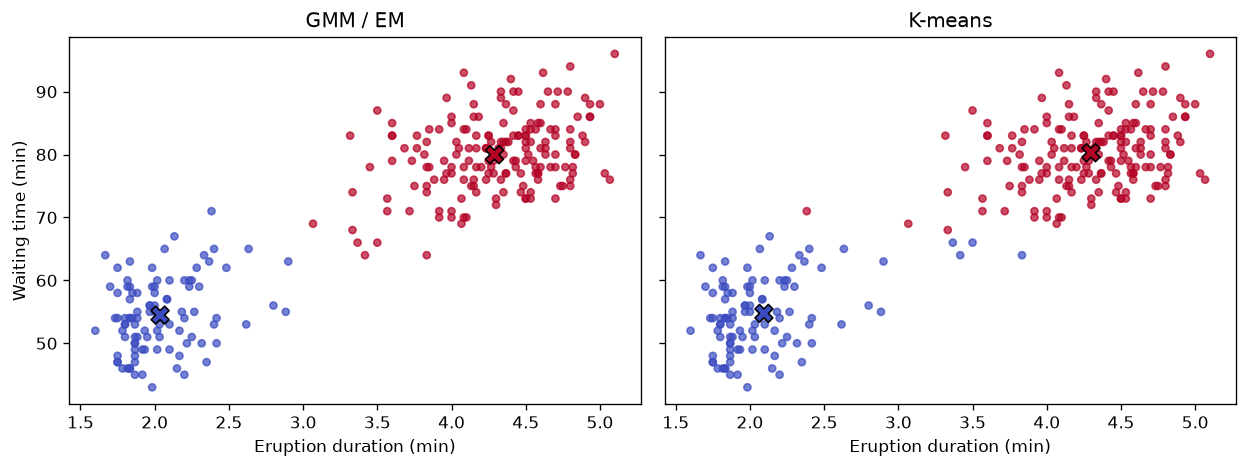

In [4]:
kmeans = KMeans(n_clusters=2, n_init=20, random_state=RNG_SEED).fit(X)
km_order = np.argsort(kmeans.cluster_centers_[:, 0])
remap = np.empty(2, dtype=int)
remap[km_order] = np.arange(2)
km_labels = remap[kmeans.labels_]
km_centers = kmeans.cluster_centers_[km_order]
disagreements = int(np.sum(km_labels != em_labels))
print("K-means centers:\n", np.round(km_centers, 5))
print("K-means hard cluster counts:", np.bincount(km_labels, minlength=2))
print("Different hard assignments:", disagreements, "of", len(X))

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0), sharex=True, sharey=True)
for ax, labels, title, centers in zip(
    axes, (em_labels, km_labels), ("GMM / EM", "K-means"),
    (em["means"], km_centers)
):
    ax.scatter(X[:, 0], X[:, 1], c=labels, cmap="coolwarm", s=18, alpha=.7)
    ax.scatter(centers[:, 0], centers[:, 1], c=[0, 1], cmap="coolwarm",
               edgecolor="black", marker="X", s=115)
    ax.set(title=title, xlabel="Eruption duration (min)")
axes[0].set_ylabel("Waiting time (min)")
fig.tight_layout()
fig.savefig(FIG / "gmm_vs_kmeans.png")
plt.show()

## Programming Exercise 2: Eigenfaces

### Parts (a) to (d): load, average, and center faces

We use the supplied `train.txt` and `test.txt` files without changing their split. Each 50 by 50 grayscale image becomes a row of 2500 pixel values, giving arrays of shape `(540, 2500)` and `(100, 2500)`. We compute the mean face from training images only, subtract that same mean from both sets, and display original and centered examples.

Train/test shapes: (540, 2500) (100, 2500)
Mean pixel of mean face: 71.1727


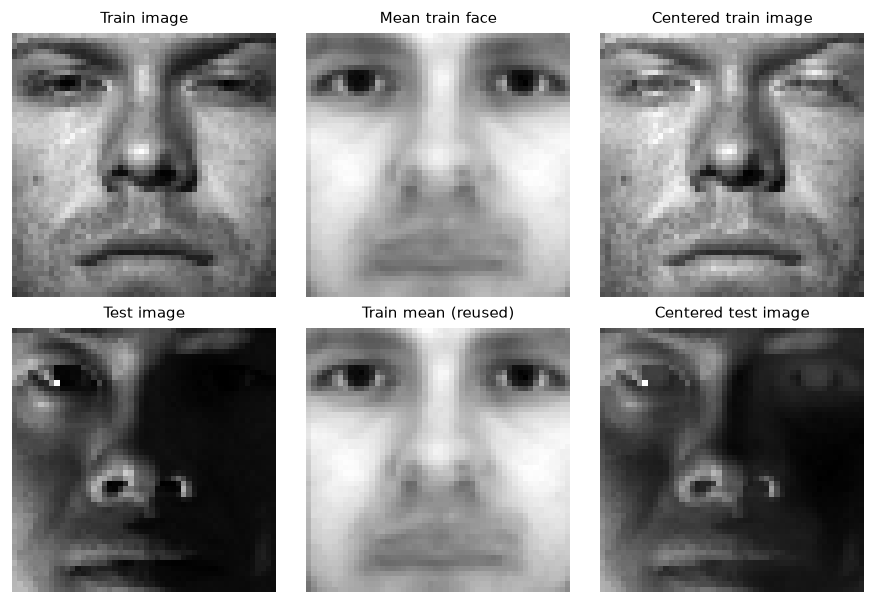

In [5]:
def load_faces(split):
    images, labels = [], []
    for line in (DATA / "faces" / f"{split}.txt").read_text().splitlines():
        relative_path, label = line.split()
        image_path = DATA / relative_path.removeprefix("./")
        with Image.open(image_path) as im:
            pixels = np.asarray(im.convert("L"), dtype=float)
        assert pixels.shape == (50, 50), image_path
        images.append(pixels.reshape(-1))
        labels.append(int(label))
    return np.vstack(images), np.asarray(labels)


train, y_train = load_faces("train")
test, y_test = load_faces("test")
assert train.shape == (540, 2500) and test.shape == (100, 2500)
assert len(np.unique(y_train)) == len(np.unique(y_test)) == 10
mean_face = train.mean(axis=0)
train_centered = train - mean_face
test_centered = test - mean_face
print("Train/test shapes:", train.shape, test.shape)
print("Mean pixel of mean face:", round(float(mean_face.mean()), 4))

fig, axes = plt.subplots(2, 3, figsize=(7.5, 5.1))
items = [
    (train[10], "Train image"), (mean_face, "Mean train face"),
    (train_centered[10], "Centered train image"),
    (test[10], "Test image"), (mean_face, "Train mean (reused)"),
    (test_centered[10], "Centered test image"),
]
for ax, (pixels, title) in zip(axes.flat, items):
    ax.imshow(pixels.reshape(50, 50), cmap="gray")
    ax.set_title(title, fontsize=9)
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIG / "faces_examples.png")
plt.show()

### Part (e): find and display the eigenfaces

For the centered training matrix $X_c$, the requested matrix $X_c^T X_c$ is 2500 by 2500. We solve the smaller 540 by 540 problem $X_cX_c^T u_j=\lambda_j u_j$ and recover $v_j=X_c^T u_j/\sqrt{\lambda_j}$. These are eigenvectors of the requested matrix because $X_c^TX_cv_j=\lambda_jv_j$.

We sort by decreasing eigenvalue and display the first ten eigenvectors as images. An eigenface describes a direction of variation across faces; its sign can be reversed without changing the PCA subspace.


Eigenface orthogonality error: 3.0697667693365067e-12
Variance explained by first 10 / 200: 0.878 0.9936


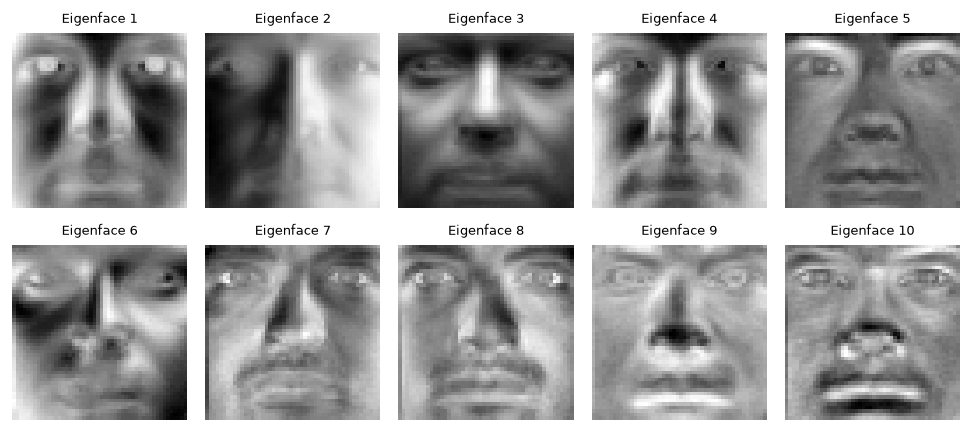

In [6]:
gram = train_centered @ train_centered.T
eigenvalues, left_vectors = eigh(gram, subset_by_index=(len(train_centered) - 200, len(train_centered) - 1))
eigenvalues = eigenvalues[::-1]
left_vectors = left_vectors[:, ::-1]
assert np.all(eigenvalues > 0)
eigenfaces = (train_centered.T @ left_vectors) / np.sqrt(eigenvalues)[None, :]
assert eigenfaces.shape == (2500, 200)
orthogonality_error = np.linalg.norm(eigenfaces.T @ eigenfaces - np.eye(200))
print("Eigenface orthogonality error:", orthogonality_error)
print("Variance explained by first 10 / 200:",
      round(float(eigenvalues[:10].sum() / np.trace(gram)), 4),
      round(float(eigenvalues.sum() / np.trace(gram)), 4))

fig, axes = plt.subplots(2, 5, figsize=(8.2, 3.8))
for i, ax in enumerate(axes.flat):
    ax.imshow(eigenfaces[:, i].reshape(50, 50), cmap="gray")
    ax.set_title(f"Eigenface {i+1}", fontsize=8)
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIG / "top_10_eigenfaces.png")
plt.show()



### Part (f): a reusable feature function

`eigenface_features` accepts any integer $r$ from 1 to the number of available eigenfaces. It returns $F=X_cV_r$ and $F_{test}=X_{test,c}V_r$, with shapes `(540, r)` and `(100, r)`. Inputs are already centered, so this function does not subtract the mean again. We explicitly call it at $r=10$ and $r=200$; taking the first $r$ columns of the latter gives the same projection.


In [7]:
def eigenface_features(train_centered, test_centered, eigenfaces, r):
    """Project already-centered training and test rows onto the top r eigenfaces."""
    if not isinstance(r, (int, np.integer)) or not 1 <= r <= eigenfaces.shape[1]:
        raise ValueError("r must be between 1 and the number of available eigenfaces")
    if train_centered.shape[1] != eigenfaces.shape[0] or test_centered.shape[1] != eigenfaces.shape[0]:
        raise ValueError("Images and eigenfaces must have matching pixel dimensions")
    basis = eigenfaces[:, :r]
    return train_centered @ basis, test_centered @ basis


F_train_10, F_test_10 = eigenface_features(train_centered, test_centered, eigenfaces, 10)
F_train, F_test = eigenface_features(train_centered, test_centered, eigenfaces, 200)
assert F_train_10.shape == (540, 10) and F_test_10.shape == (100, 10)
assert np.allclose(F_train_10, F_train[:, :10])
assert np.allclose(F_test_10, F_test[:, :10])
print("Feature shapes at r=10:", F_train_10.shape, F_test_10.shape)
print("Feature shapes at r=200:", F_train.shape, F_test.shape)


Feature shapes at r=10: (540, 10) (100, 10)
Feature shapes at r=200: (540, 200) (100, 200)


### Part (g): one-vs-rest face recognition

We standardize the projected features using training statistics, then fit ten binary logistic regression classifiers, one for each subject. The subject with the largest score is the prediction. Each value of r uses a fresh fit with C=1, the `lbfgs` solver, and at most 1000 iterations.

The cell reports the required r=10 accuracy and plots all 200 values. The observed accuracies are 78% at r=10 and 97% at r=200. The plotted maximum is descriptive; choosing r using this curve would need a separate test set for an unbiased final estimate.

Test accuracy at r=10: 0.78
Test accuracy at r=200: 0.97
Highest plotted test accuracy / r: 0.99 42


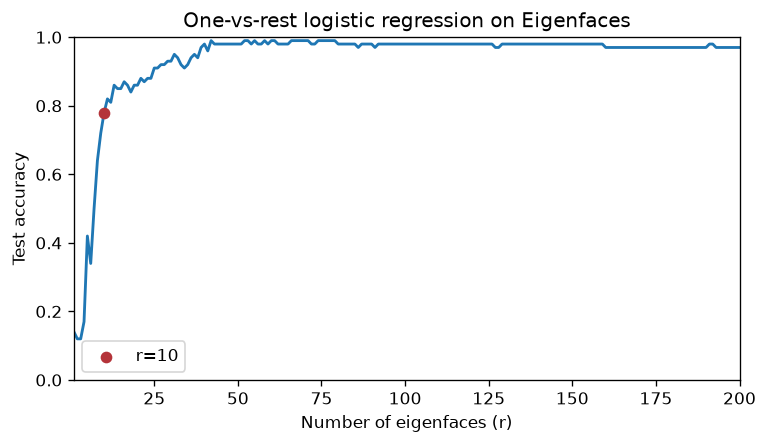

In [8]:
feature_mean = F_train.mean(axis=0)
feature_std = F_train.std(axis=0)
assert np.all(feature_std > 0)
F_train_scaled = (F_train - feature_mean) / feature_std
F_test_scaled = (F_test - feature_mean) / feature_std

accuracies = []
with warnings.catch_warnings():
    warnings.simplefilter("error", category=FutureWarning)
    for r in range(1, 201):
        classifier = OneVsRestClassifier(
            LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000)
        )
        classifier.fit(F_train_scaled[:, :r], y_train)
        predicted = classifier.predict(F_test_scaled[:, :r])
        accuracies.append(float(np.mean(predicted == y_test)))
accuracies = np.asarray(accuracies)
print("Test accuracy at r=10:", accuracies[9])
print("Test accuracy at r=200:", accuracies[199])
print("Highest plotted test accuracy / r:", accuracies.max(),
      np.flatnonzero(accuracies == accuracies.max())[0] + 1)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.plot(np.arange(1, 201), accuracies, lw=1.7)
ax.scatter([10], [accuracies[9]], color="#b43339", zorder=5, label="r=10")
ax.set(xlabel="Number of eigenfaces (r)", ylabel="Test accuracy",
       title="One-vs-rest logistic regression on Eigenfaces", xlim=(1, 200), ylim=(0, 1))
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "accuracy_vs_r.png")
plt.show()

### Save the programming results

Save the fitted GMM, K-means comparison, and face-classification measurements to `results.json`. All figures are also embedded above and saved in `figures/`.

In [9]:
results = {
    "em": {
        "seed": int(em["seed"]), "iterations": int(em["iterations"]),
        "converged": bool(em["converged"]), "log_likelihood": final_ll,
        "weights": em["weights"].tolist(), "means": em["means"].tolist(),
        "covariances": em["covariances"].tolist(),
        "cluster_counts": np.bincount(em_labels, minlength=2).tolist(),
    },
    "kmeans": {"centers": km_centers.tolist(),
               "cluster_counts": np.bincount(km_labels, minlength=2).tolist(),
               "disagreements": disagreements},
    "faces": {"train_shape": list(train.shape), "test_shape": list(test.shape),
              "orthogonality_error": float(orthogonality_error),
              "variance_first_10": float(eigenvalues[:10].sum() / np.trace(gram)),
              "variance_first_200": float(eigenvalues.sum() / np.trace(gram)),
              "accuracy_r10": float(accuracies[9]),
              "accuracy_r200": float(accuracies[199]),
              "accuracy_max": float(accuracies.max()),
              "accuracy_max_first_r": int(np.flatnonzero(accuracies == accuracies.max())[0] + 1),
              "accuracy_by_r": accuracies.tolist()},
}
(ROOT / "results.json").write_text(json.dumps(results, indent=2))
print("Saved results.json and figures/.")

Saved results.json and figures/.
